# Demo: Memory-Efficient Deep Hedging
**Natanael Alpay and Emeric Battaglia**

Imagine you are a bank selling an option. How can trading help you pay the customer—and can a neural network learn that trading strategy using less memory?

This notebook follows the presentation's **15-part order**. It includes brief explanations, editable examples, and recorded project results.

**Start here:** read the saved outputs, or choose **Run All** to recreate the teaching examples and graphs. The default uses NumPy, pandas, Matplotlib, and IPython; no model training or downloads run automatically. An optional small experiment in Section 14 uses the repository's training and plotting code.

### Imports and display settings
Keep `RUN_TRAINING = False` for the short walkthrough. To train, place this notebook in the repository root and first install its `environment/requirements.txt` in your Python environment.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown

RUN_TRAINING = False
SEED = 2026
COLORS = ["#4575B4", "#008A83"]  # Fixed pool / dynamic
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def two_bars(ax, values, title, ylabel, labels=("Fixed pool", "Dynamic")):
    bars = ax.bar(labels, values, color=COLORS, width=0.55)
    ax.bar_label(bars, fmt="%.2f", padding=4)
    ax.set(title=title, ylabel=ylabel, ylim=(0, max(values) * 1.22))
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

## 1. What is hedging?
A customer pays the bank a **premium** for the right—not the obligation—to buy a stock at a fixed **strike price** $K$ on a future date $T$.

If the stock ends at price $S_T$, the option's value is
$$Z = \max(S_T-K,0).$$

The bank owes this amount when the option is settled in cash. **Hedging** means trading assets whose gains help cover that payment. Perfect protection is possible in some idealized models; real trading leaves costs and risk.

## 2. A simple example: you are the bank
The stock costs $S_0=50$ today. At expiry it can be **40 or 60 only**. The customer may buy it for $K=50$, so the bank owes either **0 or 10**.

Buy $\delta=0.5$ shares. The stock gain is $G=\delta(S_T-S_0)$, and the remaining loss is $L=Z-G$. Both outcomes now leave the same loss of 5. A premium $p=5$ covers it:
$$\text{bank's final P\&L}=p+G-Z=p-L.$$

**Where does the purchase money come from?** Half a share costs 25. Use the premium of 5 and borrow 20. Here interest and transaction costs are zero.

In [2]:
# Try changing delta to 0 or 1 and rerunning this cell.
S0, K, premium, delta = 50.0, 50.0, 5.0, 0.5
final_prices = np.array([40.0, 60.0])
payoff = np.maximum(final_prices - K, 0)
stock_gain = delta * (final_prices - S0)
loss = payoff - stock_gain
bank_pnl = premium - loss

# Read down each column to see how the bank covers the payment.
comparison_table = pd.DataFrame(
    [payoff, stock_gain, loss, np.full_like(final_prices, premium),
     premium - payoff, bank_pnl],
    index=["Payment to customer", f"Trading gain from {delta:g} shares",
           "Remaining loss: payment minus trading gain", "Premium received",
           "Final P&L without hedge", "Final P&L with hedge"],
    columns=[f"Stock ends at {price:g}" for price in final_prices],
)
display(comparison_table.style.format("{:,.0f}").set_properties(
    subset=pd.IndexSlice[["Final P&L with hedge"], :],
    **{"font-weight": "bold", "background-color": "#e8f5f1"},
))

,Stock ends at 40,Stock ends at 60
Payment to customer,0,10
Trading gain from 0.5 shares,-5,5
Remaining loss: payment minus trading gain,5,5
Premium received,5,5
Final P&L without hedge,5,-5
Final P&L with hedge,0,0


**Takeaway:** the hedge does not make the option payment disappear. It makes the bank's trading gains offset changes in that payment. The exact hedge above relies on the two stated outcomes and the no-cost assumptions.

## 3. What makes hedging difficult?
There may be many stocks, many possible price paths, and fees every time we trade. A strategy must use information available **now**, not future prices.

For several trading dates, the same accounting becomes
$$L = Z-\sum_{t=0}^{N-1}\delta_t\cdot(S_{t+1}-S_t)+\text{trading costs}.$$

Here $\delta_t$ is the vector of holdings chosen at date $t$. The project uses **Heston** paths: both prices and their variances change over time. The next picture uses simpler **Black–Scholes-style constant-volatility paths only to illustrate uncertainty**.

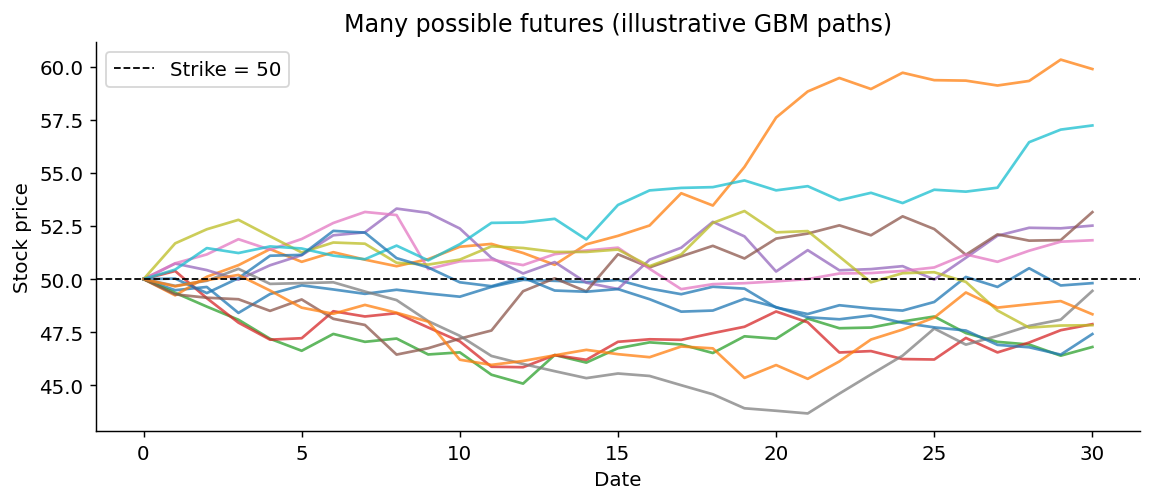

In [3]:
def illustrative_paths(rng, n_paths=12, n_dates=31, n_stocks=1):
    # Geometric Brownian motion; this is NOT the Heston experiment generator.
    dt, sigma = 1 / 365, 0.25
    increments = -0.5 * sigma**2 * dt + sigma * np.sqrt(dt) * rng.normal(
        size=(n_paths, n_dates - 1, n_stocks))
    log_paths = np.concatenate([np.zeros((n_paths, 1, n_stocks)),
                               np.cumsum(increments, axis=1)], axis=1)
    return 50 * np.exp(log_paths)

paths = illustrative_paths(np.random.default_rng(SEED))
fig, ax = plt.subplots()
ax.plot(np.arange(31), paths[:, :, 0].T, alpha=0.75)
ax.axhline(50, color="black", linestyle="--", linewidth=1, label="Strike = 50")
ax.set(xlabel="Date", ylabel="Stock price", title="Many possible futures (illustrative GBM paths)")
ax.legend(); fig.tight_layout(); plt.show()

## 4. Theoretical background: when can a hedge be exact?
**No arbitrage** means no zero-cost trade can guarantee a gain without any chance of loss. A **complete market** lets us reproduce every future payment using cash and trading.

In a frictionless finite-state market with no arbitrage, a positive cash account, and unrestricted self-financing trading, completeness is equivalent to a unique risk-neutral pricing measure $Q$. In discounted units,
$$p+G_T(\delta)=Z,\qquad p=\mathbb{E}_Q[Z].$$

$Q$ gives consistent pricing probabilities; it need not describe real-world frequencies. In our two-outcome example, each pricing probability is one-half and $p=5$. Our experiment with costs does **not** assume perfect replication.

[Background: finite-market replication and pricing](https://mathweb.ucsd.edu/~williams/courses/m194notes/chap3.pdf).

## 5. Theoretical background: why neural networks?
A neural network maps observed market information to **how much of each asset to hold**. Training adjusts its parameters to reduce the risk of the resulting losses.

The approximation result in [*Deep Hedging*](https://arxiv.org/abs/1802.03042) motivates this approach: under its finite-scenario, finite convex-risk, continuity, and information assumptions, sufficiently rich neural strategy classes can approach the best achievable risk. **Representing a good strategy does not guarantee that training finds it.**

Our three-stock experiment uses daily networks with sizes $12\to36\to36\to6$: prices, variances and previous holdings enter; new holdings leave. The six instruments are three stocks and three variance-linked claims. This fixed architecture is a practical restriction, not the full limiting theorem.

## 6. Our research question
**Can we train a good hedging strategy more efficiently, while preserving its quality?**

We compare how training paths are supplied: store a fixed pool, or generate new batches as training proceeds. The controlled three-stock comparison keeps the network architecture, instruments and training budget matched.

## 7. Fixed-pool training
First simulate a large pool, store it, and repeatedly draw training batches from it. More stocks, dates or scenarios require more storage.

The slides use $2^{17}=131{,}072$ scenarios and 31 dates (the initial date plus 30 later dates). For $d$ stocks, storing stock prices alone requires
$$131{,}072\times31\times d\times8\ \text{bytes}$$
with float64 numbers. **The scenario count is a chosen budget, not a function of the stock count.** Variances, instrument values and training allocations require additional memory.

Three stocks: 93.0 MiB for the pool; 0.182 MiB for one batch.
These are array-size calculations, not measured peak process RAM.


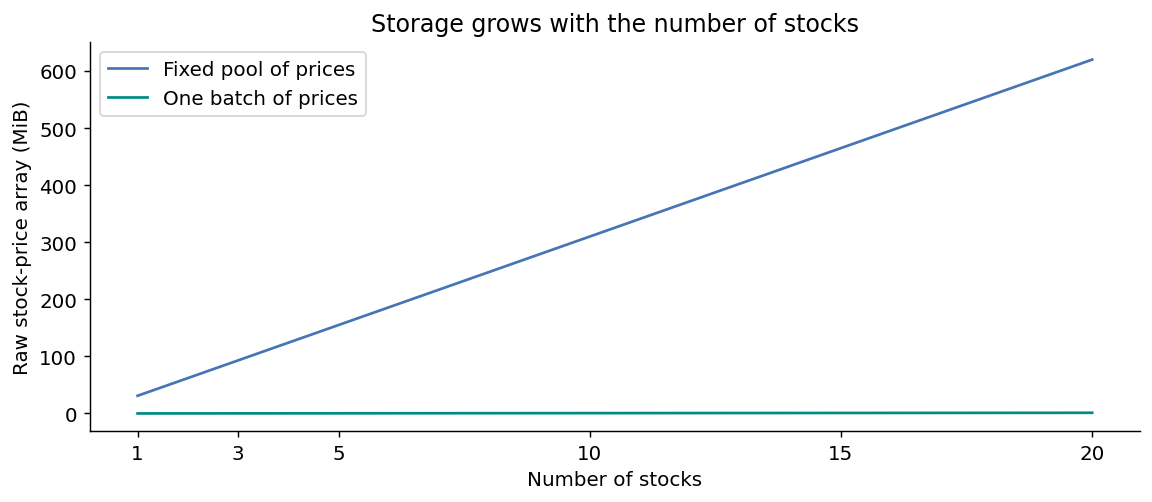

In [4]:
N_POOL, BATCH_SIZE, N_DATES = 2**17, 256, 31
stock_counts = np.arange(1, 21)
pool_mib = N_POOL * N_DATES * stock_counts * 8 / 2**20
batch_mib = BATCH_SIZE * N_DATES * stock_counts * 8 / 2**20

fig, ax = plt.subplots()
ax.plot(stock_counts, pool_mib, color=COLORS[0], label="Fixed pool of prices")
ax.plot(stock_counts, batch_mib, color=COLORS[1], label="One batch of prices")
ax.set(xlabel="Number of stocks", ylabel="Raw stock-price array (MiB)",
       title="Storage grows with the number of stocks", xticks=[1, 3, 5, 10, 15, 20])
ax.legend(); fig.tight_layout(); plt.show()
print(f"Three stocks: {pool_mib[2]:.1f} MiB for the pool; {batch_mib[2]:.3f} MiB for one batch.")
print("These are array-size calculations, not measured peak process RAM.")

## 8. Our approach: dynamic sampling
Generate **256 new scenarios**, train on that batch, then release it. This avoids retaining the full training pool, but repeated simulation takes time. Calibration, validation and test datasets still occupy memory.

This short generator illustrates the data-delivery idea; the actual training experiment uses the repository's Heston simulator.

In [5]:
def teaching_batches(n_batches=3, batch_size=256):
    rng = np.random.default_rng(SEED)
    for _ in range(n_batches):
        yield illustrative_paths(rng, n_paths=batch_size, n_stocks=3)

for i, batch in enumerate(teaching_batches(), start=1):
    print(f"Batch {i}: {batch.shape} = (scenarios, dates, stocks)")
    # A real training loop would update the network here.
    del batch

Batch 1: (256, 31, 3) = (scenarios, dates, stocks)
Batch 2: (256, 31, 3) = (scenarios, dates, stocks)
Batch 3: (256, 31, 3) = (scenarios, dates, stocks)


## 9. Initial results: memory and runtime
**Recorded slide experiment—not a timing of this notebook.** Both modes use Regular generation, three stocks and variance claims, 100 warm-up updates and 500 further updates per objective. The fixed pool contains 131,072 scenarios; the test set contains 8,192.

Peak RAM is the largest sampled memory use of the training process. It includes model state, libraries, retained datasets and temporary allocations.

Dynamic used 62.4% less peak RAM in this run.
It initially took 1.84 times as long.


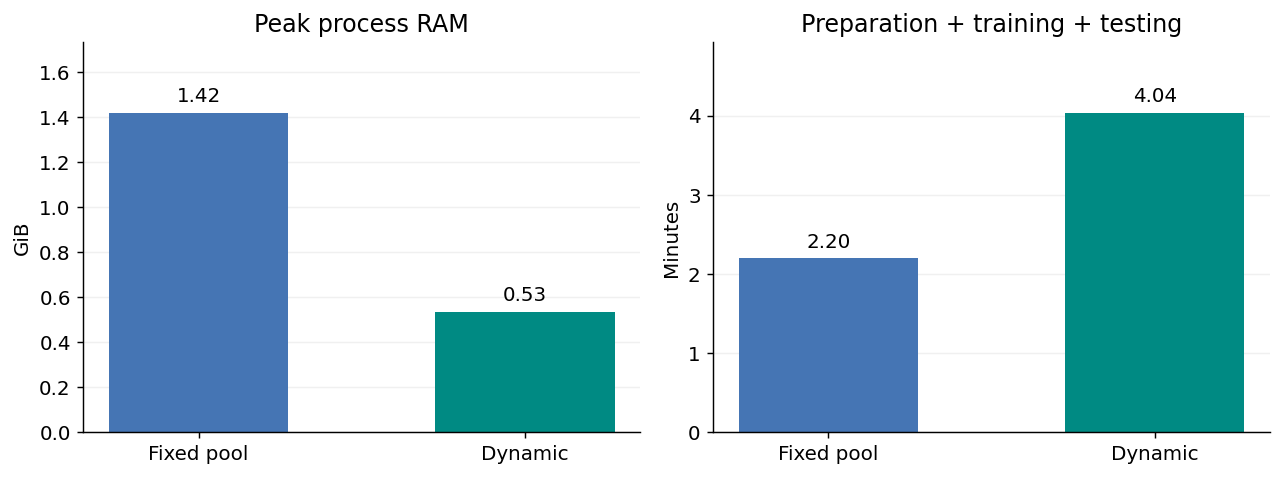

In [6]:
# Values transcribed from the presentation's recorded, isolated-process run.
peak_gib = [1.418621063232422, 0.53363037109375]
runtime_minutes = [2.196261884166718, 4.035115883516665]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
two_bars(axes[0], peak_gib, "Peak process RAM", "GiB")
two_bars(axes[1], runtime_minutes, "Preparation + training + testing", "Minutes")
fig.tight_layout(); plt.show()
print(f"Dynamic used {100 * (1 - peak_gib[1] / peak_gib[0]):.1f}% less peak RAM in this run.")
print(f"It initially took {runtime_minutes[1] / runtime_minutes[0]:.2f} times as long.")

## 10. The next challenge
**How can we reduce runtime while keeping the memory benefit?**

The network cannot update until its next batch is ready. We want to reduce the time it spends waiting for simulated paths.

## 11. Faster path generation: parallelization and a memory cache
- **Six workers** prepare independent simulation tasks concurrently.
- A small **memory cache (prefetch queue)** holds up to two waiting batches while the network trains.
- Consumed batches are released; workers prepare the next ones.

The active batch and work in progress use additional bounded memory. This cache holds *upcoming* data; it does not repeatedly reuse completed training batches. In the repository, `data_generator="Fast"`, `fast_workers=6` and `fast_prefetch=2` enable this pipeline.

## 12. Speed results
**Separate short benchmark:** medians of three repeats, 8,192 scenarios for generation, and only 10 warm-up plus 25 updates per objective for training. Both bars compare **dynamic training**, using Regular versus Fast generation.

**Elapsed time** is how long we wait. **CPU time** adds the work across workers; parallel execution can reduce waiting while using more total CPU work. These measurements depend on the machine.

Overall elapsed-time speedup: 2.30x.
Generation CPU work: 5.50 to 8.02 CPU-seconds.


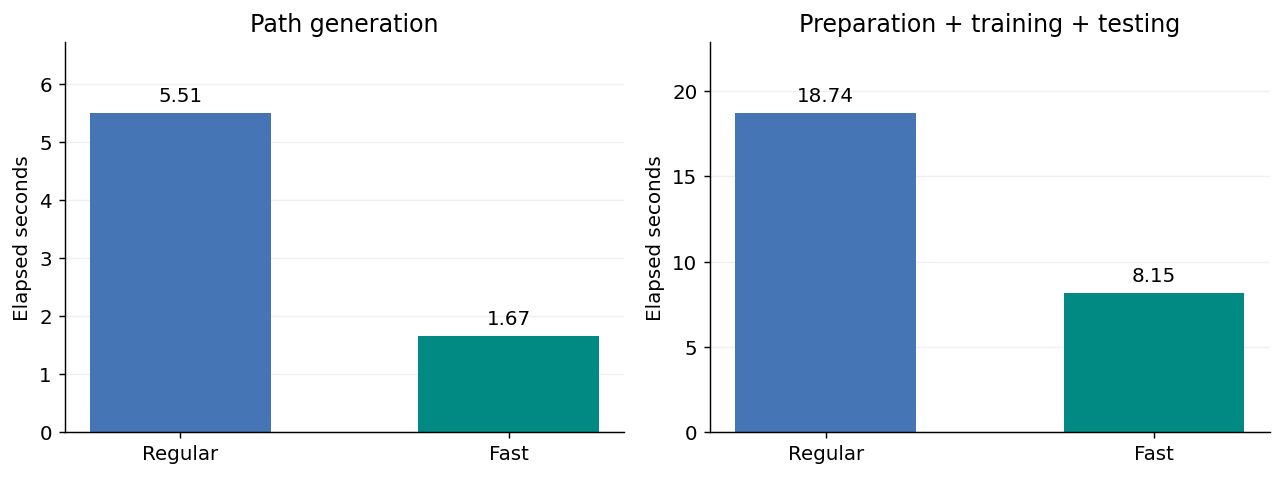

In [7]:
generation_seconds = [5.508412824001425, 1.66745899200032]
total_seconds = [18.73532113100009, 8.15061631700155]
generation_cpu_seconds = [5.498083531000001, 8.021217603]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
two_bars(axes[0], generation_seconds, "Path generation", "Elapsed seconds", ("Regular", "Fast"))
two_bars(axes[1], total_seconds, "Preparation + training + testing", "Elapsed seconds", ("Regular", "Fast"))
fig.tight_layout(); plt.show()
print(f"Overall elapsed-time speedup: {total_seconds[0] / total_seconds[1]:.2f}x.")
print(f"Generation CPU work: {generation_cpu_seconds[0]:.2f} to {generation_cpu_seconds[1]:.2f} CPU-seconds.")

## 13. How we measure hedging quality
Here $L$ is the bank's terminal loss **before subtracting the premium**. Lower risk is better.

**50%-CVaR:** the average loss in the worst half of scenarios:
$$\operatorname{CVaR}_{0.5}(L)=\inf_{\eta\in\mathbb{R}}\left\{\eta+2\mathbb{E}[(L-\eta)_+]\right\},\qquad x_+=\max(x,0).$$

**Entropic risk:** large losses receive exponentially greater weight:
$$\rho_\lambda(L)=\frac{1}{\lambda}\log\mathbb{E}[e^{\lambda L}],\qquad \lambda=1.$$

For a simple example, compare losses $[0,1,2,9]$ with $[3,3,3,3]$. Both average 3, but the first contains a much worse outcome.

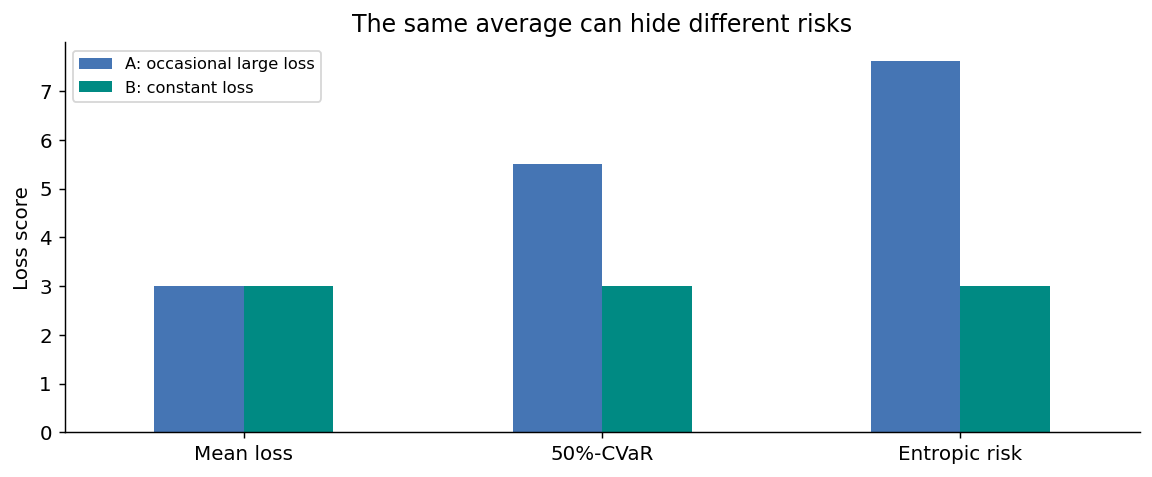

,A: occasional large loss,B: constant loss
Mean loss,3.000,3.0
50%-CVaR,5.500,3.0
Entropic risk,7.615,3.0


In [8]:
def cvar50(losses):
    values = np.sort(np.asarray(losses, dtype=float))
    if values.size == 0 or values.size % 2:
        raise ValueError("This teaching function expects a positive even number of equally weighted losses.")
    return values[values.size // 2:].mean()

def entropic_risk(losses, risk_aversion=1.0):
    if risk_aversion <= 0:
        raise ValueError("Risk aversion must be positive.")
    scaled = risk_aversion * np.asarray(losses, dtype=float)
    m = scaled.max()  # Stable evaluation: avoid exponentiating very large numbers.
    return (m + np.log(np.exp(scaled - m).mean())) / risk_aversion

toy_losses = {"A: occasional large loss": np.array([0, 1, 2, 9]),
              "B: constant loss": np.array([3, 3, 3, 3])}
risk_example = pd.DataFrame({name: [losses.mean(), cvar50(losses), entropic_risk(losses)]
                            for name, losses in toy_losses.items()},
                           index=["Mean loss", "50%-CVaR", "Entropic risk"])
display(risk_example.round(3))
ax = risk_example.plot.bar(color=COLORS, rot=0, figsize=(9, 3.8))
ax.set(ylabel="Loss score", title="The same average can hide different risks")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

## 14. Hedging-quality results
**Recorded results from 10 new paired runs.** Each pair uses matching initialization, architecture, instruments, validation paths and 8,192 test paths. Seeds change between pairs. The training budget is 100 warm-up plus 500 updates per objective. A separate policy is trained for each risk objective; validation selects its checkpoint.

Bars show means; whiskers show **one sample standard deviation**, not confidence intervals. Points show every run. These risk reruns are separate from the memory and speed benchmarks above.

In [9]:
# Recorded empirical test scores; these are data, not new training performed here.
recorded = {
    "fixed_cvar": [
        9.134575674339338,
        9.032975360353593,
        9.070295144078482,
        9.055001197685264,
        9.053920157734474,
        8.964906588628569,
        9.047949127813965,
        8.981963699666828,
        9.00069885079057,
        8.99551834256885
    ],
    "dynamic_cvar": [
        9.082758148189647,
        8.941563536372769,
        9.013773515690657,
        9.026218029195425,
        9.02526030810798,
        8.902980221091578,
        9.009863339079336,
        8.968895850472911,
        8.924043928753505,
        9.023927021032408
    ],
    "fixed_entropic": [
        18.79907211713352,
        23.042740732392083,
        29.64743789820492,
        18.84613301992736,
        16.26850147581555,
        23.523457932581728,
        41.79632237221893,
        29.65832847980129,
        21.06897642500681,
        20.238528373513763
    ],
    "dynamic_entropic": [
        24.3290991635434,
        18.194891428905542,
        18.867975033649067,
        16.290463529798387,
        16.350717147769778,
        18.791419134596172,
        15.930762351505138,
        24.759562223361915,
        20.01665366388289,
        14.32627179893333
    ]
}
paired = pd.DataFrame(recorded, index=np.arange(1, 11))
paired.index.name = 'Paired run'
display(paired.round(3))

,fixed_cvar,dynamic_cvar,fixed_entropic,dynamic_entropic
Paired run,,,,
1,9.135,9.083,18.799,24.329
2,9.033,8.942,23.043,18.195
3,9.070,9.014,29.647,18.868
4,9.055,9.026,18.846,16.290
5,9.054,9.025,16.269,16.351
6,8.965,8.903,23.523,18.791
7,9.048,9.010,41.796,15.931
8,8.982,8.969,29.658,24.760
9,9.001,8.924,21.069,20.017


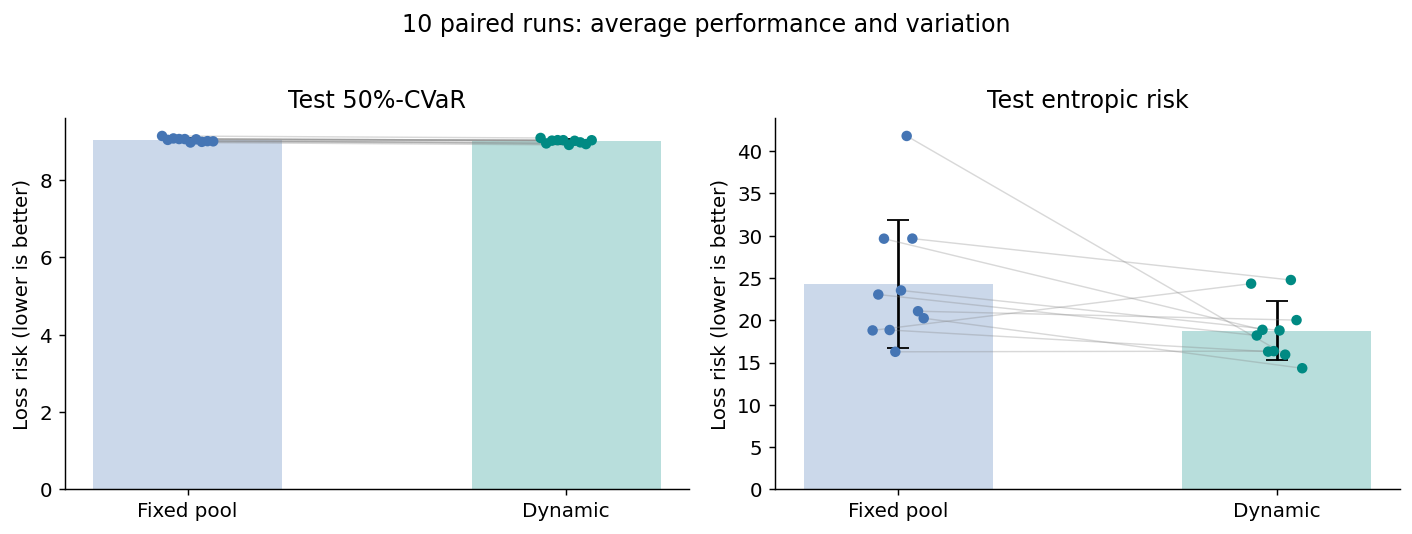

,Metric,Fixed mean,Fixed SD,Dynamic mean,Dynamic SD,Dynamic lower / 10
0,Test 50%-CVaR,9.034,0.05,8.992,0.056,9
1,Test entropic risk,24.289,7.58,18.786,3.472,8


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
summary_rows = []
for ax, objective, title in zip(axes, ["cvar", "entropic"], ["Test 50%-CVaR", "Test entropic risk"]):
    fixed = paired[f"fixed_{objective}"].to_numpy()
    dynamic = paired[f"dynamic_{objective}"].to_numpy()
    means = [fixed.mean(), dynamic.mean()]
    sd = [fixed.std(ddof=1), dynamic.std(ddof=1)]
    ax.bar([0, 1], means, yerr=sd, capsize=6, color=COLORS, alpha=0.28, width=0.5)
    for i, (f, d) in enumerate(zip(fixed, dynamic)):
        jitter = (i - 4.5) * 0.015
        ax.plot([jitter, 1 + jitter], [f, d], color="gray", alpha=0.3, linewidth=0.8)
        ax.scatter([jitter, 1 + jitter], [f, d], c=COLORS, s=23, zorder=3)
    ax.set(xticks=[0, 1], xticklabels=["Fixed pool", "Dynamic"],
           ylabel="Loss risk (lower is better)", title=title, ylim=(0, None))
    summary_rows.append([title, means[0], sd[0], means[1], sd[1], int((dynamic < fixed).sum())])
fig.suptitle("10 paired runs: average performance and variation", y=1.02)
fig.tight_layout(); plt.show()
display(pd.DataFrame(summary_rows, columns=["Metric", "Fixed mean", "Fixed SD", "Dynamic mean",
                                          "Dynamic SD", "Dynamic lower / 10"]).round(3))

**What do we learn?** CVaR remains close: about **9.034 versus 8.992**. Dynamic has lower average entropic risk (**18.79 versus 24.29**) and wins 8 of 10 pairs, but the results vary substantially. The approximate 95% paired interval for dynamic minus fixed entropic risk is $[-11.47,0.46]$, so the advantage is encouraging rather than conclusive.

Entropic scores can be dominated by very few extreme losses. These short training runs do not establish optimality; in 8 of 10 runs for each mode, the separately CVaR-trained policy actually had a lower test entropic score than the entropic-trained policy.

### Optional: train a small version yourself
Set `RUN_TRAINING = True` near the top and rerun the notebook **from the repository root**. This uses the same `generalNN`, `Settings` and `plots` interfaces as the other notebooks.

The smaller pool, validation/test samples and update counts below make this a classroom experiment. **Its results will differ from the recorded research results.** It trains with transaction costs and the actual Heston simulator. Start with `BACKEND = "Regular"`; changing it to `"Fast"` enables the parallel pipeline.

In [11]:
quick_experiments = []
if RUN_TRAINING:
    from dataclasses import replace
    from scripts.general_nn import generalNN
    from scripts.settings import Settings, StockSettings, NetworkSettings
    from scripts import plots

    BACKEND = "Regular"
    stocks = (
        StockSettings(name="Stock1", initial_price=100, strike=100, initial_variance=0.04,
                      long_run_variance=0.04, mean_reversion=1.0, vol_of_vol=2.0, correlation=-0.7),
        StockSettings(name="Stock2", initial_price=50, strike=50, initial_variance=0.02,
                      long_run_variance=0.02, mean_reversion=1.2, vol_of_vol=1.8, correlation=-0.6),
        StockSettings(name="Stock3", initial_price=200, strike=200, initial_variance=0.06,
                      long_run_variance=0.06, mean_reversion=0.8, vol_of_vol=2.2, correlation=-0.5),
    )
    settings = Settings(stocks=stocks, network=NetworkSettings((36, 36), "tanh", True),
                        warmup_updates=10, continuation_updates=25, validation_interval=5,
                        normalization_size=512, validation_size=512, test_size=1024,
                        static_training_size=2048, number_of_replicates=1)
    fixed_model = generalNN("paper", settings, dynamic_data=False, data_generator=BACKEND,
                            fast_workers=6, fast_prefetch=2, name="Fixed pool (classroom run)")
    dynamic_model = generalNN("ours", replace(settings, instruments=fixed_model.settings.instruments),
                              dynamic_data=True, data_generator=BACKEND,
                              fast_workers=6, fast_prefetch=2, name="Dynamic (classroom run)")
    quick_experiments = [fixed_model, dynamic_model]
    for model in quick_experiments:
        model.train(verbose=False)
        model.evaluate()
    assert fixed_model.metadata["test_data_id"] == dynamic_model.metadata["test_data_id"]
    plots.plot_results_grid(quick_experiments, figsize=(11, 10))
else:
    print("Optional training is off. All earlier graphs use teaching examples or labeled recorded results.")

Optional training is off. All earlier graphs use teaching examples or labeled recorded results.


## 15. Bonus: comparison with a theoretical benchmark
In a no-cost Heston market, model sensitivities provide a useful hedge for comparison. The graph below is a **separate recorded single-call experiment**, with daily rebalancing and 8,192 common test paths.

A **variance claim** is a tradable contract linked to variance. Trading it can help hedge uncertainty that stock trading alone leaves behind. Agreement with a model-based hedge is a useful check—not proof that a network finds the optimum.

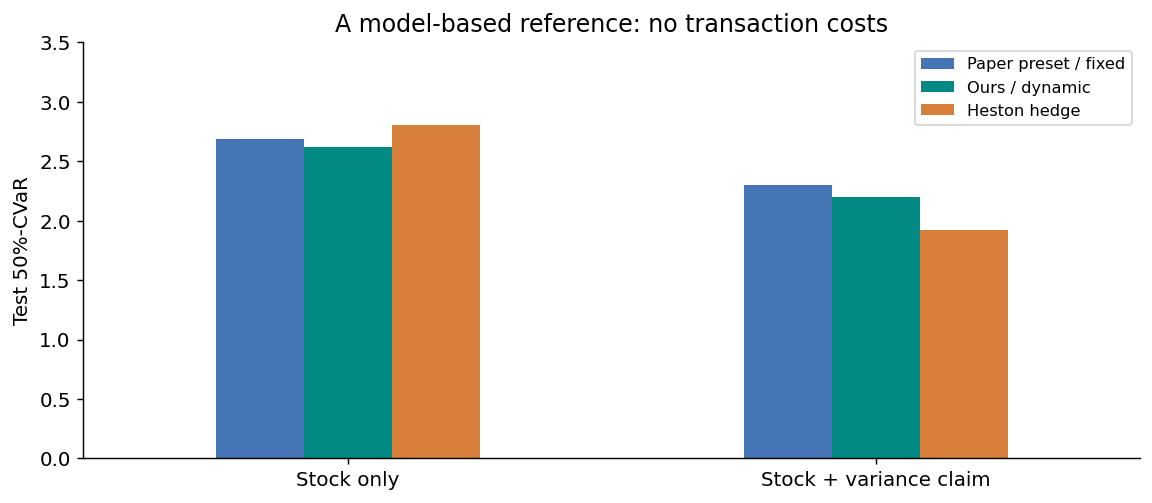

,Paper preset / fixed,Ours / dynamic,Heston hedge
Stock only,2.688,2.623,2.803
Stock + variance claim,2.301,2.199,1.926


In [12]:
# Separate no-cost single-call results from the presentation.
benchmark = pd.DataFrame({
    "Paper preset / fixed": [2.687664458916415, 2.300544635965913],
    "Ours / dynamic": [2.622598693133007, 2.199188344654169],
    "Heston hedge": [2.803244669902454, 1.925639504612708],
}, index=["Stock only", "Stock + variance claim"])
ax = benchmark.plot.bar(color=[*COLORS, "#D77E38"], rot=0, figsize=(9, 4))
ax.set(ylabel="Test 50%-CVaR", title="A model-based reference: no transaction costs", ylim=(0, 3.5))
ax.legend(fontsize=9); plt.tight_layout(); plt.show()
display(benchmark.round(3))

With both instruments, the Heston hedge has the lowest observed CVaR in this example. Daily trading and numerical approximations prevent a perfect-replication claim. The single-call neural presets also differ, so this bonus does not isolate the effect of dynamic sampling.

**Takeaway:** dynamic sampling reduces stored training data; parallel generation reduces waiting; held-out risk measurements check whether the resulting hedge remains useful.

**Try next:** change the half-share hedge in Section 2, increase the stock count in Section 7, or run the optional training example. What changes, and what stays the same?

### Sources and experiment notes
- [Project repository](https://github.com/AlpayNatanael/Deep-Hedging-Implementation) · [Small portfolio notebook](https://github.com/AlpayNatanael/Deep-Hedging-Implementation/blob/04ea9d384b210422b25ad1effe8bdcd6befc9e59/Small_Portfolio_Comparison.ipynb) · [Path-generation notebook](https://github.com/AlpayNatanael/Deep-Hedging-Implementation/blob/04ea9d384b210422b25ad1effe8bdcd6befc9e59/Path_Generation_Comparison.ipynb) · [Single-call notebook](https://github.com/AlpayNatanael/Deep-Hedging-Implementation/blob/04ea9d384b210422b25ad1effe8bdcd6befc9e59/Single_Call_Comparison.ipynb).
- Code checked at commit `04ea9d384b210422b25ad1effe8bdcd6befc9e59`. Recorded memory, speed and Heston values come from the presentation's numerical runs at that commit. Their budgets are labeled above; they are not interchangeable benchmarks.
- The ten-pair risk scores come from the follow-up experiment: add `1000 * pair` to original seeds 7000 (initialization), 10100 (training), 20200 (validation), and 40400 (test), for pairs 1 through 10. The original single-run slide result is excluded from this average.
- Full measurements, source provenance and instructions are included in the companion `Demo_Review.zip`. To add this notebook to the repository later, only `Demo.ipynb` is required: its recorded data and displayed figures are embedded.

[Natanael's website](https://alpaynatanael.github.io/) · [LinkedIn](https://www.linkedin.com/in/natanael-alpay-99802a19a/) · [Project code](https://github.com/AlpayNatanael/Deep-Hedging-Implementation)